In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv(r"C:\Users\bisha\Downloads\All Codes (3)\Clustering\mall.csv")

In [3]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
x=df.iloc[:,[3,4]].values

## Using k-mean cluster

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Window

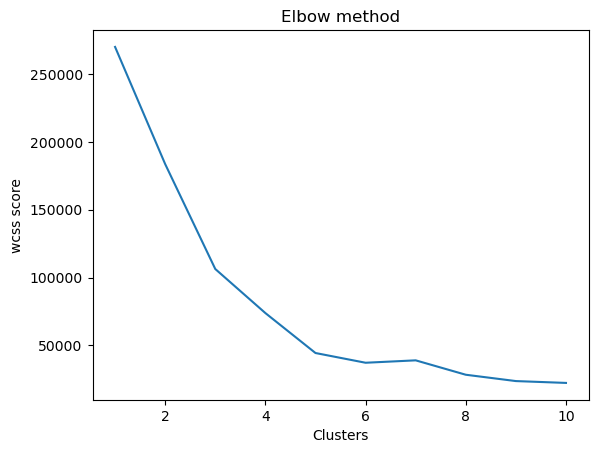

In [5]:
#Elbow method
from sklearn.cluster import KMeans
wcss=[]
for i in range(1,11):
    kmeans=KMeans(n_clusters=i)
    kmeans.fit(x)
    wcss.append(kmeans.inertia_)
plt.plot(range(1,11),wcss)
plt.title('Elbow method')
plt.xlabel('Clusters')
plt.ylabel('wcss score')
plt.show()

In [6]:
kmeans=KMeans(n_clusters=5)
y_kmeans=kmeans.fit_predict(x)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


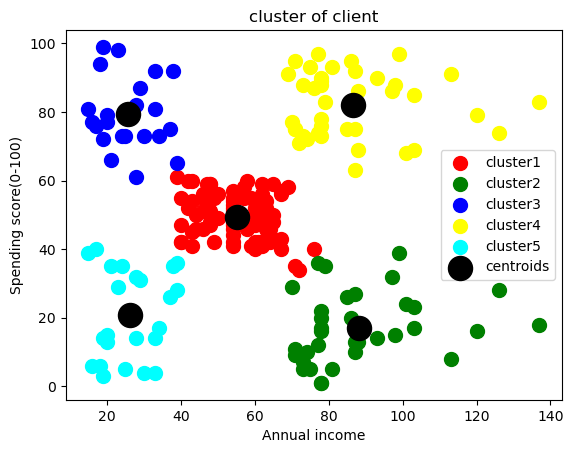

In [7]:
plt.scatter(x[y_kmeans==0,0],x[y_kmeans==0,1],s=100,c='red',label='cluster1')
plt.scatter(x[y_kmeans==1,0],x[y_kmeans==1,1],s=100,c='green',label='cluster2')
plt.scatter(x[y_kmeans==2,0],x[y_kmeans==2,1],s=100,c='blue',label='cluster3')
plt.scatter(x[y_kmeans==3,0],x[y_kmeans==3,1],s=100,c='yellow',label='cluster4')
plt.scatter(x[y_kmeans==4,0],x[y_kmeans==4,1],s=100,c='cyan',label='cluster5')
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],s=300,c='black',label='centroids')
plt.title('cluster of client')
plt.xlabel('Annual income')
plt.ylabel('Spending score(0-100)')
plt.legend()
plt.show()

###### As we see the cluster 3 and 5 have some data point which is far from centroid
this is beacause we use 5 as no. of cluster but we see a elbow at 6 also lets try with 6

In [17]:
kmeans=KMeans(n_clusters=7)
y_kmeans2=kmeans.fit_predict(x)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


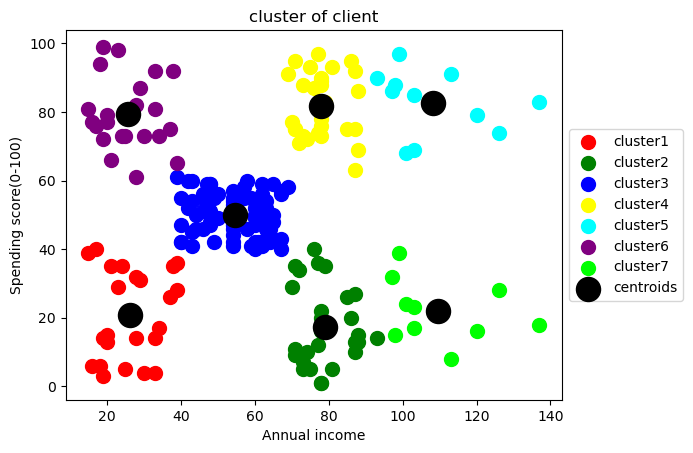

In [18]:
plt.scatter(x[y_kmeans2==0,0],x[y_kmeans2==0,1],s=100,c='red',label='cluster1')
plt.scatter(x[y_kmeans2==1,0],x[y_kmeans2==1,1],s=100,c='green',label='cluster2')
plt.scatter(x[y_kmeans2==2,0],x[y_kmeans2==2,1],s=100,c='blue',label='cluster3')
plt.scatter(x[y_kmeans2==3,0],x[y_kmeans2==3,1],s=100,c='yellow',label='cluster4')
plt.scatter(x[y_kmeans2==4,0],x[y_kmeans2==4,1],s=100,c='cyan',label='cluster5')
plt.scatter(x[y_kmeans2==5,0],x[y_kmeans2==5,1],s=100,c='purple',label='cluster6')
plt.scatter(x[y_kmeans2==6,0],x[y_kmeans2==6,1],s=100,c='lime',label='cluster7')
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],s=300,c='black',label='centroids')
plt.title('cluster of client')
plt.xlabel('Annual income')
plt.ylabel('Spending score(0-100)')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

###### From the graph we have 7 types of class:-
- High Annual salary High spending score->Cluster 5
- Medium Annual salary High spending score->cluster 4
- Low Annual salary High spending score ->cluster 6
- Medium Annual salary Medium spending score->cluster 3
- High Annual salary low spending score->Cluster 7
- Medium Annual salary low spending score->cluster 2
- Low Annual salary low spending score ->cluster 1

### Using Hierarchical Clustering

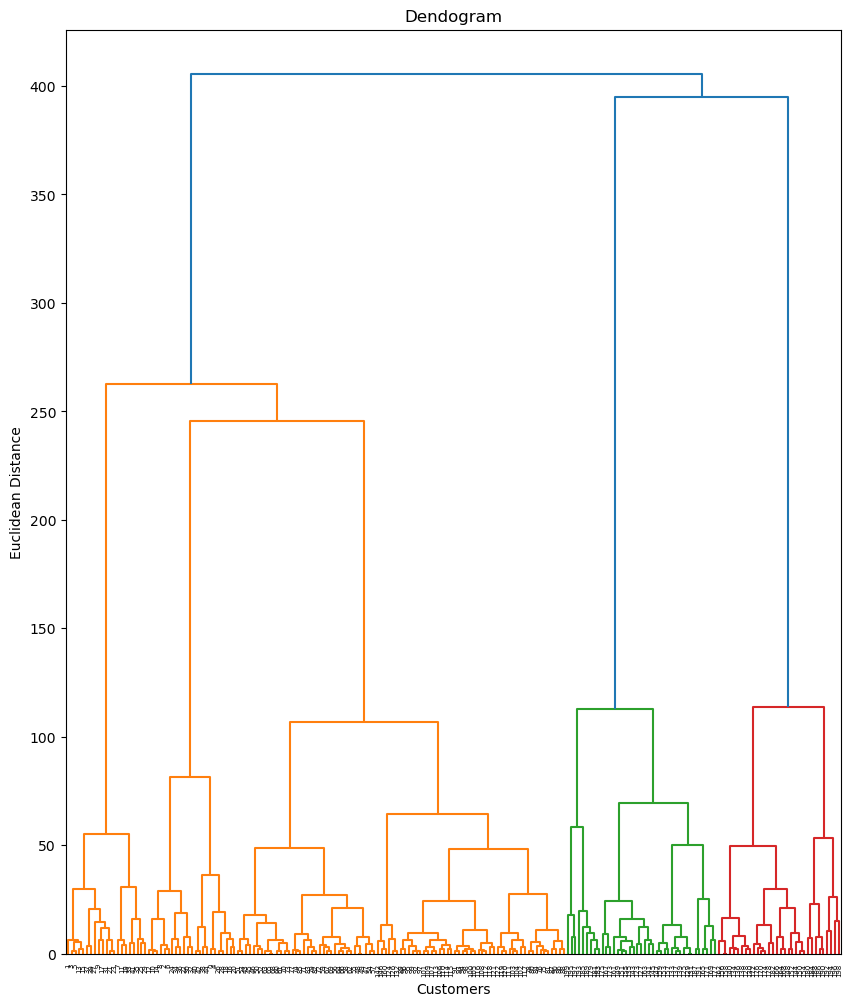

In [10]:
# using dendogram to find optimal numbers of clusters
import scipy.cluster.hierarchy as sch
plt.figure(figsize=(10,12))
dendogram=sch.dendrogram(sch.linkage(x,method='ward'))
plt.title('Dendogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distance')
plt.show()

In [11]:
from sklearn.cluster import AgglomerativeClustering
hc=AgglomerativeClustering(n_clusters=5,metric='euclidean',linkage='ward')
y_hc=hc.fit_predict(x)

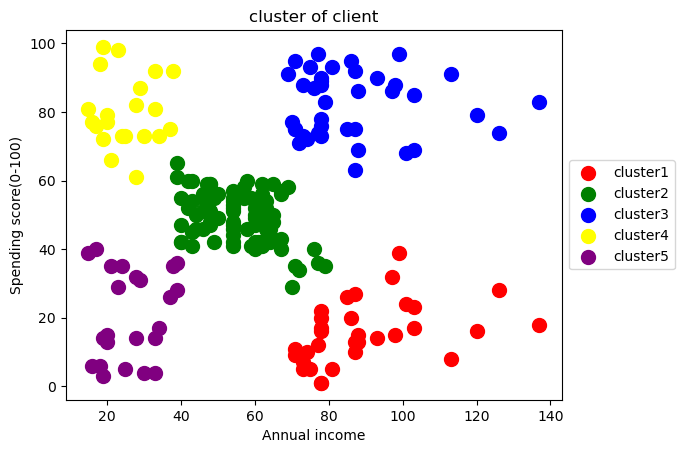

In [12]:
#Visualing the clusters
plt.scatter(x[y_hc==0,0],x[y_hc==0,1],s=100,c='red',label='cluster1')
plt.scatter(x[y_hc==1,0],x[y_hc==1,1],s=100,c='green',label='cluster2')
plt.scatter(x[y_hc==2,0],x[y_hc==2,1],s=100,c='blue',label='cluster3')
plt.scatter(x[y_hc==3,0],x[y_hc==3,1],s=100,c='yellow',label='cluster4')
plt.scatter(x[y_hc==4,0],x[y_hc==4,1],s=100,c='purple',label='cluster5')
plt.title('cluster of client')
plt.xlabel('Annual income')
plt.ylabel('Spending score(0-100)')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()